In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# Is Italy's deficit surprise unusual? A placebo ranking among the EU27
Notebook 38 looked at Italy alone: how the budget laws were financed and how the deficit compared with the government's own targets. With ten years and one country it cannot say whether the misses were large *for Italy* or typical of the period, and a single country has no clustered test (Italy is one cluster). The project's rule for such claims is a **placebo ranking**: compute the same quantity for every other member and see where Italy falls.

**Reference.** The programmatic targets of notebook 38 exist only for Italy (draft budgetary plans differ in layout and content), so here the reference is the **European Commission's autumn forecast** of the year before the budget year (`sources/ec_forecasts.py`: the statistical annexes of autumn 2016 to 2025, one table per variable for all member states, so budget years 2017-2025; the autumn 2015 annex, in the old layout, adds budget year 2016 as a sensitivity window only). It is published after the draft budgetary plans and normally includes their measures: an outside view of the plan, not the government's own target. For Italy the two references are put side by side below.

**Surprise** = outturn (Eurostat, latest vintage) minus forecast, in % of GDP, for net borrowing and for its parts (revenue shortfall, primary-expenditure overrun, interest overrun); positive = worse than forecast. Two measures: the raw surprise and the **idiosyncratic** one, minus the median of the *other* 26 members in the same year (the common shocks of 2020-23 move everyone). **Ranks** are among the 27 members (1 = largest overrun, one-sided p = rank / 27, so the smallest possible p is 0.037). Windows fixed before the ranks were computed: 2017-25 without 2020, and 2021-23 (the years of the building credits); BH over the 16 tests of these two windows (4 components, 2 measures); the other windows are shown without a q. A per-country sign-flip screen of the mean idiosyncratic surprise, with a sign-randomised null, checks the machinery.

**Limits to keep in mind.** The Eurostat outturn is the latest vintage: revisions (for Italy the treatment of the building credits, decided in 2023-24) enter the surprise, so part of it is accounting, not policy. The ratios are in % of GDP and a GDP error moves them; the Italian decomposition of notebook 38 separates that term, here a denominator split at the end of the robustness section does it for every member (forecast GDP built from the forecast growth rates, see there). Cyprus 2018 (bank support) and similar one-offs are in the sample. Everything is descriptive: a forecast error is not a policy effect.

forecast table: 8304 rows; vintages [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)] | variables ['deflator', 'expenditure', 'interest', 'net_lending', 'real_growth', 'revenue']
countries with a deficit surprise in every year 2017-25: 27 of 27 | in 2016 (autumn 2015 annex): 27
deficit surprise by year (pp of GDP, positive = larger deficit than forecast): Italy against the other 26


,Italy,median_others,min_others,max_others
year,,,,
2016,0.1,-0.85,-3.8,0.6
2017,0.1,-1.45,-4.0,0.8
2018,0.4,-0.60,-2.9,4.8
2019,-1.4,-0.05,-4.4,2.0
2020,7.1,5.65,0.1,10.9
2021,1.1,-1.75,-6.6,3.7
2022,2.3,-1.25,-4.1,1.6
2023,3.5,-0.85,-3.7,2.6
2024,-1.0,-0.55,-3.6,3.9


accounting identity, |deficit - (revenue + primary expenditure + interest parts)| over all country-years: {'count': 268.0, 'mean': 0.044, 'std': 0.056, 'min': 0.0, '25%': 0.0, '50%': 0.0, '75%': 0.1, 'max': 0.2}
Italy's rank by year, deficit surprise (of 27): {2016: 5, 2017: 5, 2018: 2, 2019: 24, 2020: 8, 2021: 3, 2022: 1, 2023: 1, 2024: 17, 2025: 19}


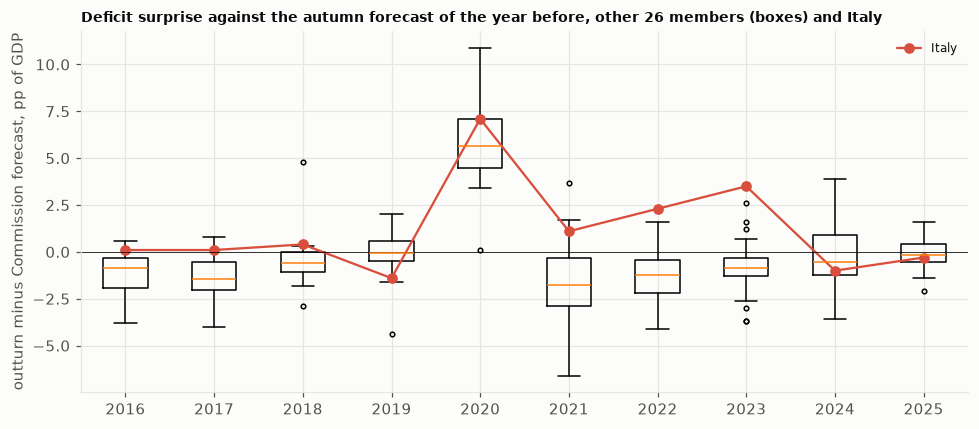

In [2]:
from cifresignificative.studies.italy_productivity.analysis import budget_xc as BX, budget as BU, experiments as ex
xres = ex.run_budget_xc_all()
F = BX.load_forecasts(); print("forecast table:", len(F), "rows; vintages", sorted(F.vintage.unique()), "| variables", sorted(F.variable.unique()))
x1 = xres["x1_surprises"]; S = x1[x1.component.eq("deficit")].pivot(index="year", columns="iso3", values="value")
print("countries with a deficit surprise in every year 2017-25:", int(S.loc[2017:].notna().all().sum()), "of", S.shape[1], "| in 2016 (autumn 2015 annex):", int(S.loc[2016].notna().sum()))
print("deficit surprise by year (pp of GDP, positive = larger deficit than forecast): Italy against the other 26"); 
tab = pd.DataFrame({"Italy": S.ITA, "median_others": S.drop(columns="ITA").median(axis=1), "min_others": S.drop(columns="ITA").min(axis=1), "max_others": S.drop(columns="ITA").max(axis=1)}); display(tab.round(2))
print("accounting identity, |deficit - (revenue + primary expenditure + interest parts)| over all country-years:", xres["x9_identity"].round(3).to_dict("records")[0])
yr = xres["x3_yearly_ranks"]; print("Italy's rank by year, deficit surprise (of 27):", yr[(yr.component == "deficit") & (yr.measure == "raw")].set_index("year")["rank"].to_dict())
fig, ax = plt.subplots(figsize=(9, 4)); o = S.drop(columns="ITA")
ax.boxplot([o.loc[y].dropna() for y in S.index], positions=S.index, widths=.5, showfliers=True, flierprops=dict(markersize=3)); ax.plot(S.index, S.ITA, "o-", color="#d94f3d", label="Italy"); ax.axhline(0, color="k", lw=.5)
ax.set_ylabel("outturn minus Commission forecast, pp of GDP"); ax.set_title("Deficit surprise against the autumn forecast of the year before, other 26 members (boxes) and Italy", fontsize=9); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## Italy's rank, by component and window

In [3]:
r = xres["x2_italy_rank"]
print("Italy's rank among the 27 (1 = largest overrun); primary windows carry a BH q over the 16 tests:"); display(r[r.measure.eq("raw") | r.measure.eq("idiosyncratic")].set_index(["component", "measure", "window"])[["value", "median_others", "rank", "n", "p", "q_value"]].round(3))
prim = r[r.primary]; print("primary family:", len(prim), "tests | smallest p", round(float(prim.p.min()), 3), "| smallest q", round(float(prim.q_value.min()), 3), "| tests with q <= 0.05:", int((prim.q_value <= 0.05).sum()))
print("rank 1 or 2 among 27:"); display(r[r["rank"] <= 2][["component", "measure", "window", "rank", "p", "q_value"]].round(3))
print("sensitivity, adding budget year 2016 (autumn 2015 annex; not primary, no q): deficit, Italy's rank among 27"); display(r[r.window.eq("2016-25 without 2020") & r.component.eq("deficit")][["measure", "value", "median_others", "rank", "p"]].round(3))
print("Italy's deficit surprise in 2016 (raw):", round(float(S.loc[2016, "ITA"]), 2), "| median of the other 26:", round(float(S.loc[2016].drop("ITA").median()), 2), "| rank by year:", yr[(yr.component == "deficit") & (yr.measure == "raw") & (yr.year == 2016)]["rank"].tolist())

Italy's rank among the 27 (1 = largest overrun); primary windows carry a BH q over the 16 tests:


value  \
component                   measure       window                        
deficit                     raw           2017-25 without 2020  0.588   
                                          2021-23               2.300   
                                          2017-19              -0.300   
                                          2024-25              -0.650   
                                          2016-25 without 2020  0.533   
                            idiosyncratic 2017-25 without 2020  1.419   
                                          2021-23               3.583   
                                          2017-19               0.400   
                                          2024-25              -0.300   
                                          2016-25 without 2020  1.367   
revenue_shortfall           raw           2017-25 without 2020  0.350   
                                          2021-23               1.133   
                                          2017-19              -0.067   
                                          2024-25              -0.200   
                                          2016-25 without 2020  0.378   
                            idiosyncratic 2017-25 without 2020  0.775   
                                          2021-23               1.683   
                                          2017-19               0.350   
                                          2024-25               0.050   
                                          2016-25 without 2020  0.772   
primary_expenditure_overrun raw           2017-25 without 2020  0.288   
                                          2021-23               0.967   
                                          2017-19              -0.067   
                                          2024-25              -0.200   
                                          2016-25 without 2020  0.222   
                            idiosyncratic 2017-25 without 2020  0.713   
                                          2021-23               2.150   
                                          2017-19               0.100   
                                          2024-25              -0.525   
                                          2016-25 without 2020  0.656   
interest_overrun            raw           2017-25 without 2020 -0.013   
                                          2021-23               0.267   
                                          2017-19              -0.167   
                                          2024-25              -0.200   
                                          2016-25 without 2020 -0.033   
                            idiosyncratic 2017-25 without 2020  0.031   
                                          2021-23               0.283   
                                          2017-19              -0.067   
                                          2024-25              -0.200   
                                          2016-25 without 2020  0.017   

                                                                median_others  \
component                   measure       window                                
deficit                     raw           2017-25 without 2020         -0.606   
                                          2021-23                      -1.250   
                                          2017-19                      -0.500   
                                          2024-25                      -0.350   
                                          2016-25 without 2020         -0.717   
                            idiosyncratic 2017-25 without 2020          0.197   
                                          2021-23                      -0.050   
                                          2017-19                       0.208   
                                          2024-25                       0.075   
                                          2016-25 without 2020          0.083   
revenue_shortfall        

primary family: 16 tests | smallest p 0.037 | smallest q 0.254 | tests with q <= 0.05: 0
rank 1 or 2 among 27:


,component,measure,window,rank,p,q_value
0,deficit,raw,2017-25 without 2020,2,0.074,0.254
1,deficit,raw,2021-23,1,0.037,0.254
4,deficit,raw,2016-25 without 2020,2,0.074,NaN
5,deficit,idiosyncratic,2017-25 without 2020,2,0.074,0.254
6,deficit,idiosyncratic,2021-23,1,0.037,0.254
9,deficit,idiosyncratic,2016-25 without 2020,2,0.074,NaN


sensitivity, adding budget year 2016 (autumn 2015 annex; not primary, no q): deficit, Italy's rank among 27


,measure,value,median_others,rank,p
4,raw,0.533,-0.717,2,0.074
9,idiosyncratic,1.367,0.083,2,0.074


Italy's deficit surprise in 2016 (raw): 0.1 | median of the other 26: -0.85 | rank by year: [5]


## Robustness: euro-area members only, other horizons, and the two references for Italy

In [4]:
ea = xres["x4_euro_area_rank"]; print("deficit surprise, Italy's rank among the 20 euro-area members (p only: a q over four tests would mislead):"); display(ea.set_index(["measure", "window"])[["value", "median_others", "rank", "n", "p"]].round(3))
print("horizon (same years 2018-25 for every lead; lead 0 = the autumn forecast of the budget year itself, 2 = two autumns before):"); display(xres["x5_lead"].set_index(["lead", "window", "measure"])[["value", "median_others", "rank", "n", "p"]].round(3))
tv = xres["x6_two_views"].set_index("year"); print("Italy: miss against the Commission's forecast and against the government's own target (pp of GDP):"); display(tv.round(2))
print("mean gap between the two references (Commission deficit forecast minus government target), 2017-25:", round(float(tv.reference_gap.mean()), 2), "| 2021-23:", round(float(tv.loc[2021:2023, "reference_gap"].mean()), 2))

deficit surprise, Italy's rank among the 20 euro-area members (p only: a q over four tests would mislead):


value  median_others  rank   n     p
measure       window                                                    
raw           2017-25 without 2020  0.588         -0.850     1  20  0.05
              2021-23               2.300         -1.500     1  20  0.05
              2017-19              -0.300         -0.500     7  20  0.35
              2024-25              -0.650         -0.700     9  20  0.45
              2016-25 without 2020  0.533         -0.744     1  20  0.05
idiosyncratic 2017-25 without 2020  1.500          0.075     1  20  0.05
              2021-23               3.733         -0.067     1  20  0.05
              2017-19               0.267          0.000     6  20  0.30
              2024-25              -0.000         -0.050     9  20  0.45
              2016-25 without 2020  1.422          0.133     1  20  0.05

horizon (same years 2018-25 for every lead; lead 0 = the autumn forecast of the budget year itself, 2 = two autumns before):


value  median_others  rank   n  \
lead window                 measure                                         
0    2021-23                raw            1.433         -1.200     1  27   
                            idiosyncratic  2.583         -0.108     1  27   
     2018-2025 without 2020 raw            0.514         -0.529     2  27   
                            idiosyncratic  1.150          0.086     1  27   
1    2021-23                raw            2.300         -1.250     1  27   
                            idiosyncratic  3.583         -0.050     1  27   
     2018-2025 without 2020 raw            0.657         -0.479     2  27   
                            idiosyncratic  1.400          0.257     2  27   
2    2021-23                raw            3.700         -0.067     2  27   
                            idiosyncratic  3.333         -0.550     2  27   
     2018-2025 without 2020 raw            1.186          0.186     3  27   
                            idiosyncratic  1.321          0.336     3  27   

                                               p  
lead window                 measure               
0    2021-23                raw            0.037  
                            idiosyncratic  0.037  
     2018-2025 without 2020 raw            0.074  
                            idiosyncratic  0.037  
1    2021-23                raw            0.037  
                            idiosyncratic  0.037  
     2018-2025 without 2020 raw            0.074  
                            idiosyncratic  0.074  
2    2021-23                raw            0.074  
                            idiosyncratic  0.074  
     2018-2025 without 2020 raw            0.111  
                            idiosyncratic  0.111

Italy: miss against the Commission's forecast and against the government's own target (pp of GDP):


,outturn_deficit,commission_surprise,commission_deficit,government_deficit,government_surprise,reference_gap
year,,,,,,
2016,2.4,0.1,2.3,2.2,0.2,0.1
2017,2.5,0.1,2.4,2.3,0.2,0.1
2018,2.2,0.4,1.8,1.6,0.6,0.2
2019,1.5,-1.4,2.9,2.4,-0.9,0.5
2020,9.4,7.1,2.3,2.2,7.2,0.1
2021,8.9,1.1,7.8,7.0,1.9,0.8
2022,8.1,2.3,5.8,5.6,2.5,0.2
2023,7.1,3.5,3.6,4.5,2.6,-0.9
2024,3.4,-1.0,4.4,4.3,-0.9,0.1


mean gap between the two references (Commission deficit forecast minus government target), 2017-25: 0.13 | 2021-23: 0.03


In [5]:
loo = [{"years": "-".join(map(str, w)), "measure": m, **BX.italy_rank(X, w)} for w in ([2021, 2022], [2022, 2023], [2021, 2023]) for m, X in (("raw", S), ("idiosyncratic", BX.idiosyncratic(S)))]
print("the 2021-23 window with one year left out (deficit surprise, Italy's rank among 27):"); display(pd.DataFrame(loo).set_index(["years", "measure"])[["value", "median_others", "rank", "n", "p"]].round(3))
print("Italy's rank in the single years 2022 and 2023 (raw):", {int(y): int(yr[(yr.component == "deficit") & (yr.measure == "raw") & (yr.year == y)]["rank"].iloc[0]) for y in (2022, 2023)})

the 2021-23 window with one year left out (deficit surprise, Italy's rank among 27):


value  median_others  rank   n      p
years     measure                                             
2021-2022 raw             1.70         -1.600     2  27  0.074
          idiosyncratic   3.20         -0.237     2  27  0.074
2022-2023 raw             2.90         -0.825     1  27  0.037
          idiosyncratic   3.95          0.125     1  27  0.037
2021-2023 raw             2.30         -1.050     1  27  0.037
          idiosyncratic   3.60          0.213     1  27  0.037

Italy's rank in the single years 2022 and 2023 (raw): {2022: 1, 2023: 1}


## Robustness: an early outturn instead of the latest vintage

In [6]:
fe, rv = xres["x10_first_estimate"], xres["x10_revisions"]
print("deficit surprise with the Commission's estimate of the year just ended (autumn forecast of B+1) or the latest Eurostat vintage as the outturn, budget years 2017-24; Italy's rank among 27:"); display(fe.set_index(["outturn", "window", "measure"])[["value", "median_others", "rank", "n", "p"]].round(3))
print("revision of the deficit after the early estimate (latest minus early, pp of GDP; positive = larger deficit), Italy against the others:"); display(rv.set_index("year").round(2))

deficit surprise with the Commission's estimate of the year just ended (autumn forecast of B+1) or the latest Eurostat vintage as the outturn, budget years 2017-24; Italy's rank among 27:


value  median_others  rank  \
outturn        window               measure                                     
early estimate 2021-23              raw            1.733         -1.050     1   
                                    idiosyncratic  3.017          0.142     1   
               2017-24 without 2020 raw            0.471         -0.750     2   
                                    idiosyncratic  1.357          0.118     2   
latest vintage 2021-23              raw            2.300         -1.250     1   
                                    idiosyncratic  3.583         -0.050     1   
               2017-24 without 2020 raw            0.714         -0.721     2   
                                    idiosyncratic  1.643          0.168     2   

                                                    n      p  
outturn        window               measure                   
early estimate 2021-23              raw            27  0.037  
                                    idiosyncratic  27  0.037  
               2017-24 without 2020 raw            27  0.074  
                                    idiosyncratic  27  0.074  
latest vintage 2021-23              raw            27  0.037  
                                    idiosyncratic  27  0.037  
               2017-24 without 2020 raw            27  0.074  
                                    idiosyncratic  27  0.074

revision of the deficit after the early estimate (latest minus early, pp of GDP; positive = larger deficit), Italy against the others:


,italy,median_others,max_others
year,,,
2017,0.1,0.0,0.7
2018,0.0,0.0,0.6
2019,-0.1,0.0,0.7
2020,-0.2,-0.2,0.5
2021,1.7,-0.1,0.2
2022,0.1,-0.1,0.3
2023,-0.1,0.0,0.4
2024,0.0,0.0,0.6


## Robustness: the GDP denominator
The surprise is a difference of ratios, so a GDP forecast error moves it. Forecast nominal GDP of the budget year B is rebuilt from the latest outturn of B-2 and the Commission's autumn forecast of B-1 for real growth and the GDP deflator in B-1 and B (the annexes give growth rates, not levels). With D the deficit in euro, surprise = (D_out - D_fc) / G_out + (D_fc / G_fc) (G_fc / G_out - 1): the second term (`denominator`) is the part due to the GDP error alone, the first (`level`) is the miss of the deficit in euro at the outturn GDP. Ranks only (primary windows), no q: this is a decomposition of the tested quantity, not a new family.

In [7]:
dr, sp = xres["x11_denominator_ranks"], xres["x11_italy_split"]
print("Italy's rank among 27 for the deficit surprise and its two parts (1 = largest):"); display(dr.set_index(["part", "measure", "window"])[["value", "median_others", "rank", "n", "p"]].round(3))
print("Italy by year (pp of GDP): surprise = denominator + level:"); display(sp.set_index("year").round(2))

Italy's rank among 27 for the deficit surprise and its two parts (1 = largest):


value  median_others  rank  \
part        measure       window                                             
surprise    raw           2017-25 without 2020  0.588         -0.606     2   
                          2021-23               2.300         -1.250     1   
            idiosyncratic 2017-25 without 2020  1.419          0.197     2   
                          2021-23               3.583         -0.050     1   
denominator raw           2017-25 without 2020 -0.123         -0.081    20   
                          2021-23              -0.316         -0.192    21   
            idiosyncratic 2017-25 without 2020 -0.047         -0.002    21   
                          2021-23              -0.123          0.005    21   
level       raw           2017-25 without 2020  0.711         -0.527     1   
                          2021-23               2.616         -1.157     1   
            idiosyncratic 2017-25 without 2020  1.439          0.177     1   
                          2021-23               3.641         -0.192     1   

                                                 n      p  
part        measure       window                           
surprise    raw           2017-25 without 2020  27  0.074  
                          2021-23               27  0.037  
            idiosyncratic 2017-25 without 2020  27  0.074  
                          2021-23               27  0.037  
denominator raw           2017-25 without 2020  27  0.741  
                          2021-23               27  0.778  
            idiosyncratic 2017-25 without 2020  27  0.778  
                          2021-23               27  0.778  
level       raw           2017-25 without 2020  27  0.037  
                          2021-23               27  0.037  
            idiosyncratic 2017-25 without 2020  27  0.037  
                          2021-23               27  0.037

Italy by year (pp of GDP): surprise = denominator + level:


,surprise,denominator,level
year,,,
2016,0.1,-0.01,0.11
2017,0.1,-0.03,0.13
2018,0.4,0.01,0.39
2019,-1.4,0.04,-1.44
2020,7.1,0.20,6.90
2021,1.1,-0.47,1.57
2022,2.3,-0.30,2.60
2023,3.5,-0.17,3.67
2024,-1.0,-0.05,-0.95


## Which countries are unusual? Per-country screen and its null

In [8]:
sc = xres["x7_screen"]; print("mean idiosyncratic deficit surprise, 2017-25 without 2020 (sign-flip p, BH q over countries); top 8 and bottom 3:"); display(pd.concat([sc.head(8), sc.tail(3)]).round(3))
print("discoveries (q <= 0.05):", int(sc.significant.sum()), "of", len(sc), "| Italy's rank in the screen:", int(sc.index[sc.iso3.eq("ITA")][0]) + 1)
nl = xres["x8_null"]; print("sign-randomised null,", len(nl), "shuffles: mean discoveries", round(float(nl.discoveries.mean()), 3), "| shuffles with a discovery", round(float((nl.discoveries > 0).mean()), 3), "| share of p < 0.05", round(float(nl.share_p_below_005.mean()), 3))
r2 = xres["x2_italy_rank"]; comp = r2[(r2.measure == "idiosyncratic") & (r2.window == "2021-23")].set_index("component")[["value", "rank", "p"]]
S3 = {c: x1[x1.component.eq(c)].pivot(index="year", columns="iso3", values="value") for c in BX.COMPONENTS}
big = pd.DataFrame({c: BX.window_mean(BX.idiosyncratic(s), [2021, 2022, 2023]) for c, s in S3.items()}).dropna()
print("2021-23, idiosyncratic means, the five largest deficit overruns and their parts:"); display(big.sort_values("deficit", ascending=False).head(5).round(2))

mean idiosyncratic deficit surprise, 2017-25 without 2020 (sign-flip p, BH q over countries); top 8 and bottom 3:


,iso3,mean,p,q_value,significant
0,HUN,1.531,0.016,0.140,False
1,ITA,1.419,0.112,0.320,False
2,AUT,0.931,0.072,0.316,False
3,ROU,0.862,0.270,0.488,False
4,LVA,0.794,0.387,0.580,False
5,POL,0.694,0.250,0.488,False
6,SWE,0.663,0.070,0.316,False
7,FRA,0.650,0.119,0.320,False
24,LTU,-1.000,0.108,0.320,False
25,NLD,-1.019,0.008,0.110,False


discoveries (q <= 0.05): 0 of 27 | Italy's rank in the screen: 2
sign-randomised null, 200 shuffles: mean discoveries 0.0 | shuffles with a discovery 0.0 | share of p < 0.05 0.046


2021-23, idiosyncratic means, the five largest deficit overruns and their parts:


,deficit,revenue_shortfall,primary_expenditure_overrun,interest_overrun
iso3,,,,
ITA,3.58,1.68,2.15,0.28
HUN,2.88,1.60,1.02,0.63
LVA,2.28,-1.42,4.05,-0.08
BGR,1.37,2.52,-0.62,-0.15
AUT,1.35,-1.27,2.92,-0.00


### The members' own draft budgetary plans as a second reference
The Commission's forecast is the outside view; the government's own plan is the inside one. `sources/dbp_euro.py` downloads the English copies of the October draft budgetary plans of the euro-area members from the Commission's yearly pages (119 files, 2018-2025) and reads the planned net lending of the general government from the macro table: three B.9 rows whose values add up (rest of the world = private sector + general government) find the right row whatever its label. 51 plans are verified this way (9 countries: Austria, Cyprus, Greece, Italy, Lithuania, Latvia, Malta, the Netherlands, Portugal; 4-9 a year), ten more are label-only and left out, 58 are not parsed (new templates, fractions, wrapped labels). Italy's eight parsed plans match `deficit_targets.csv`. Three identity-only rows of 2021 that differ from the Commission's forecast of that autumn by 2.4-6.3 points are dropped as misreadings. The sample is thin, so each rank is shown next to the Commission-based rank for exactly the same country-years.


In [9]:
dp = xres["x12_dbp_plans"]; dr = xres["x13_dbp_ranks"]
print("plans used (country-years):", len(dp), "| countries:", sorted(dp.iso3.unique()), "| plans per year:", dp.groupby("year").size().to_dict())
print("Italy's plan and surprise against it by year (net lending, % of GDP):"); display(dp[dp.iso3.eq("ITA")].round(2))
print("Italy's rank among the countries with plans (1 = the largest overrun), own plan against the Commission forecast on the same country-years:"); display(dr.drop(columns="countries").round(2))


plans used (country-years): 51 | countries: ['AUT', 'CYP', 'GRC', 'ITA', 'LTU', 'LVA', 'MLT', 'NLD', 'PRT'] | plans per year: {2016: 1, 2017: 1, 2018: 4, 2019: 7, 2020: 7, 2021: 6, 2022: 8, 2023: 8, 2024: 5, 2025: 4}
Italy's plan and surprise against it by year (net lending, % of GDP):


,year,iso3,plan_net_lending,surprise_vs_plan
17,2016,ITA,-2.2,0.2
18,2017,ITA,-2.3,0.2
19,2018,ITA,-1.6,0.6
20,2019,ITA,-2.4,-0.9
21,2020,ITA,-2.2,7.2
22,2021,ITA,-7.0,1.9
23,2022,ITA,-5.6,2.5
24,2023,ITA,-3.4,3.7
25,2024,ITA,-4.3,-0.9
26,2025,ITA,-3.3,-0.2


Italy's rank among the countries with plans (1 = the largest overrun), own plan against the Commission forecast on the same country-years:


,window,reference,measure,italy,rank,n,p,median_others
0,2018-25 without 2020,own plan,raw,0.96,1,7,0.14,-0.63
1,2018-25 without 2020,own plan,idiosyncratic,1.86,1,7,0.14,-0.27
2,2018-25 without 2020,"Commission forecast, same country-years",raw,0.66,1,7,0.14,-0.89
3,2018-25 without 2020,"Commission forecast, same country-years",idiosyncratic,1.56,1,7,0.14,-0.06
4,2021-23,own plan,raw,2.70,1,8,0.12,-0.97
5,2021-23,own plan,idiosyncratic,4.03,1,8,0.12,-0.07
6,2021-23,"Commission forecast, same country-years",raw,2.30,1,8,0.12,-1.80
7,2021-23,"Commission forecast, same country-years",idiosyncratic,3.63,1,8,0.12,-0.77


## Takeaways (deficit surprise against the Commission's autumn forecast, 27 members, budget years 2017-2025; descriptive)
- **Data.** The statistical annexes of the ten autumn forecasts of 2016-2025 give net lending, revenue, expenditure and interest for all 27 members (the autumn 2015 annex has the old layout and is read separately: it adds budget year 2016, used only as a sensitivity window, so the primary windows start in 2017). Every member has a surprise in every year, and the three parts add up to the deficit surprise within 0.04 points on average (largest gap 0.2: rounding of the published figures; Denmark's total revenue of 2024 and 2025 is missing from Eurostat's release of 21 October 2026, so the revenue windows that contain those years rank 26 members). As a check of the parsing, the estimate column of each annex agrees with the latest Eurostat outturn within 0.08 to 0.31 points on average.
- **Adding budget year 2016 changes nothing.** With the autumn 2015 annex as a sensitivity window (2016-25 without 2020, not primary, no q) Italy is second of 27 on the deficit surprise (raw +0.53, median of the others -0.72; p 0.074), as in the primary window; Italy's own surprise in 2016 is +0.10 against a median of -0.85 for the others (rank 5).
- **Italy's deficit overrun of 2021-23 was the largest of the 27.** Against the autumn forecast of the year before, the outturn deficit was above the forecast by 2.30 points of GDP on average (median of the other 26: -1.25); minus the other members' yearly median it is 3.58 (the next are Hungary 2.88 and Latvia 2.28). The one-sided placebo p is 1/27 = 0.037, the smallest the design allows, and it does not survive false-discovery control: over the 16 pre-specified tests (two windows, four components, two measures) the smallest q is 0.254 and none reaches 0.05. Among the 20 euro-area members Italy is also first (p 0.05).
- **The rank does not hinge on one year or one horizon.** In 2022 and 2023 taken singly Italy is first (+2.3 and +3.5 against medians of -1.25 and -0.85 for the others; 2021 is third, +1.1). Leaving one year out of 2021-23 gives rank 2 (2021-22) or 1 (2022-23, 2021 and 2023). Against the forecast of the budget year itself the rank is still first (1.43 points); against the forecast of two years before it is second (3.70).
- **The result does not depend on the outturn vintage.** With the Commission's own estimate of the year just ended (autumn forecast of B+1, budget years 2017-24) instead of the latest Eurostat figures, 2021-23 is still first of 27 (raw +1.73, median of the others -1.05; idiosyncratic +3.02) and the period without 2020 still second (raw +0.47). What the later revisions changed is mostly one number: Italy's 2021 deficit was revised up by 1.7 points of GDP (the other members' median -0.1, largest +0.2), which is the accounting treatment of the building credits; in every other year Italy's revision is within 0.2.
- **A GDP forecast error does not explain it; at constant GDP it is larger.** Rebuilding forecast nominal GDP from the forecast growth and deflator, the denominator term is negative in Italy in 2021-23 (-0.47, -0.30, -0.17: inflation made the economy larger than forecast, which lowers every ratio), so the miss of the deficit in euro at the outturn GDP is +1.57, +2.60 and +3.67 points; for 2021-23 Italy is first on that level miss (raw 2.62, idiosyncratic 3.64, p 0.037) and the denominator term itself ranks 21 of 27. Without 2020 the whole period is also first on the level miss (raw 0.71, p 0.037) where the plain surprise is second (0.59). The forecast GDP is a rebuilt level, not a published one (latest outturn of B-2 times forecast growth), so these figures carry that approximation.
- **Outside those years Italy is unremarkable.** 2017-19 rank 10 (raw -0.30, median of the others -0.50), 2024-25 rank 15. Without 2020 the whole period gives rank 2 (0.59 raw, 1.42 idiosyncratic; p 0.074, q 0.254): the 2021-23 years carry it. In 2020 the pandemic overrun was 7.1 points, rank 8 (median of the others 5.65).
- **It is spread over the parts, not one of them.** In 2021-23 the idiosyncratic means are 1.68 for the revenue shortfall (rank 5 of 27), 2.15 for primary expenditure (rank 3) and 0.28 for interest (rank 3); none of them is first, and none has a q below 0.25. Other members have larger single parts (Latvia 4.05 and Austria 2.92 on primary expenditure; Bulgaria 2.52 on revenue), so what is unusual in Italy is the sum. This is compatible with the Italian account of notebook 38 (capital transfers for the building credits) but does not test it: no other country has that item here, and the outturn is the latest Eurostat vintage, whose treatment of the credits was revised, so part of the surprise is accounting.
- **The two references agree for Italy.** The Commission's deficit forecast was on average 0.13 points above the government's own target (0.03 in 2021-23; the largest gaps +0.8 in 2021 and -0.9 in 2023), so the miss is about the same against either (2021-23: +1.1, +2.3, +3.5 against the Commission, +1.9, +2.5, +2.6 against the government).
- **The country screen cannot discover anything by design; it only orders.** The sign-flip screen of the mean idiosyncratic surprise (2017-25 without 2020) finds 0 of 27 discoveries, but with 8 years the smallest attainable p is about 0.008 and the smallest q over 27 countries about 0.11 (reached by Denmark, -2.42, and the Netherlands, -1.02, which tie): a real persistent difference could not pass either. The order is still informative: Hungary +1.53 (p 0.016, q 0.14) first and Italy second (+1.42, p 0.112, q 0.32), with Denmark and the Netherlands at the bottom (deficits smaller than forecast). The sign-randomised null gives 0 discoveries in 200 runs and 4.6% of p-values below 0.05, so the p-values are calibrated even if the screen has no power at this size.
- **The governments' own plans give the same placement, on a thin sample.** From 51 verified draft budgetary plans of 9 euro-area members (4-9 a year), Italy's 2021-23 deficit exceeded its own plan by 2.70 points on average (4.03 against the median of the others in the same year): first of 8 countries (p 1/8; the Commission-based figure on the same country-years is 2.30, first of 8 too). Over 2018-25 without 2020 it is 0.96 (1.86 idiosyncratic), first of 7; the Commission-based rank on those country-years is also first on both measures. Italy's 2023 plan is the outgoing government's October one (-3.4; the November update said -4.5, which would shorten the 2023 surprise from 3.7 to 2.6). No test is possible with 7-8 countries (the smallest p is 1/8) and the countries with parsable plans are not a random draw: this is a second look, not a confirmation. The plan table: `data/external/dbp_targets.csv`.
- **Limits.** One-sided ranks among 27 cannot go below 0.037 and Italy is one country, so this is a placement, not a calibrated test; the 16 tests are strongly dependent (BH is conservative here). The reference is the Commission's forecast (policy as known in the autumn), not each government's plan; ratios are in % of GDP and a GDP error moves them (separated in the denominator split, which rests on a forecast GDP level rebuilt from the latest outturn of B-2 and the forecast growth, not a published level); Cyprus 2018 and similar one-offs are in the sample; ten years, with 2020 and the 2021-23 recovery dominating. All associations are descriptive: a forecast error is not a policy effect.
